Demo Developed by T. Mayer 6/16/26

Stuff to check out:

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html

https://sites.gatech.edu/omscs7641/2024/02/16/tutorial-on-hyperparameter-tuning-using-scikit-learn/

https://dev.to/anurag629/gridsearchcv-in-scikit-learn-a-comprehensive-guide-2a72

https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html

heres is the code for Tasseled cap

In [ ]:

function calculateL8ToaTasseledCapIndices(imageCollection) {

  imageCollection = imageCollection.map(routine.maskL7L8);

  var image = imageCollection.median();

  var bands = image.select('blue', 'green', 'red', 'nir', 'swir1', 'swir2');
  //Coefficients are only for Landsat 8 TOA
  var brightness_coefficents= ee.Image([0.3029, 0.2786, 0.4733, 0.5599, 0.508, 0.1872]);
  var greenness_coefficents= ee.Image([-0.2941, -0.243, -0.5424, 0.7276, 0.0713, -0.1608]);
  var wetness_coefficents= ee.Image([0.1511, 0.1973, 0.3283, 0.3407, -0.7117, -0.4559]);
  var fourth_coefficents= ee.Image([-0.8239, 0.0849, 0.4396, -0.058, 0.2013, -0.2773]);
  var fifth_coefficents= ee.Image([-0.3294, 0.0557, 0.1056, 0.1855, -0.4349, 0.8085]);
  var sixth_coefficents= ee.Image([0.1079, -0.9023, 0.4119, 0.0575, -0.0259, 0.0252]);

  var brightness = image.expression('(bands * BRIGHTNESS)',{'bands': bands, 'BRIGHTNESS': brightness_coefficents});
  var greenness = image.expression('(bands * GREENNESS)',{'bands': bands,'GREENNESS': greenness_coefficents});
  var wetness = image.expression('(bands * WETNESS)', {'bands': bands,'WETNESS': wetness_coefficents});
  var fourth = image.expression('(bands * FOURTH)', {'bands': bands,'FOURTH': fourth_coefficents});
  var fifth = image.expression( '(bands * FIFTH)', {'bands': bands,'FIFTH': fifth_coefficents });
  var sixth = image.expression('(bands * SIXTH)', {'bands': bands,'SIXTH': sixth_coefficents });

  brightness = brightness.reduce(ee.call('Reducer.sum'));
  greenness = greenness.reduce(ee.call('Reducer.sum'));
  wetness = wetness.reduce(ee.call('Reducer.sum'));
  fourth = fourth.reduce(ee.call('Reducer.sum'));
  fifth = fifth.reduce(ee.call('Reducer.sum'));
  sixth = sixth.reduce(ee.call('Reducer.sum'));
  return ee.Image(brightness).addBands([greenness, wetness, fourth, fifth, sixth])
                             .rename(['brightness','greenness','wetness','fourth','fifth','sixth']);
}


# Threshold Grid Search for Surface Water Indices (NDVI / NDWI / MNDWI / LST / TCW)

**Goal:** for a given study area, find the index threshold that best separates a target
land-cover class (e.g. open water, or open water + wetland) from everything else, using
a labeled reference (truth) dataset of pixels with known land-cover class.

**Why grid search, and not just "use the textbook threshold"?** Published thresholds
(e.g. NDWI > 0, MNDWI > 0) are derived from other sensors, other regions, other seasons.
Index magnitude is sensitive to local atmospheric conditions, sensor band placement,
turbidity, emergent vegetation, and land cover mix — so the value that maximizes
separability in *your* scene is rarely exactly the canonical one. A grid search treats
the threshold as a free parameter, sweeps it across the index's observed range, scores
each candidate value against your reference labels, and keeps the value that maximizes
whatever skill metric you care about (F1, Youden's J, IoU, etc).

**Structure of this notebook**

1. Build a synthetic stand-in for your monthly composite + truth dataset (swap this for
   your real `ee.Image.sampleRegions()` output later — see the last section).
2. Define the binary target and the "direction" of each index (does water sit above or
   below the threshold?).
3. Split into train/test so thresholds aren't tuned and evaluated on the same pixels.
4. Implement the single-index grid search core (the actual algorithm).
5. Run it per index with k-fold cross-validation for a stable threshold estimate.
6. Visualize the threshold–performance curves.
7. Validate the chosen thresholds on the held-out test set.
8. Bonus: a 2D joint grid search showing how two indices interact (and why full joint
   search over all 5 indices isn't really tractable by brute force).
9. Notes on plugging in your real GEE-derived pixel sample.


In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import train_test_split, StratifiedKFold
import math
from shapely.geometry import box
from pyproj import Transformer
import folium
from folium import FeatureGroup, LayerControl

pd.set_option("display.width", 120)
RANDOM_SEED = 42


## 1. Synthetic data: monthly composite indices + truth labels

This mimics what you'd get from `ee.Image.sampleRegions()` run against your monthly
median composite, sampled at points/polygons from a truth dataset: one row per pixel,
one column per index, and a `landcover` label.

The class-conditional means/stds below are rough but physically plausible — wetland
sits between open water and vegetation on NDVI/NDWI/MNDWI/TCW (mixed emergent
vegetation + standing water), and is cooler than urban/bare but warmer than open
water on LST. **Replace `PARAMS` with values you'd expect for Sewanee** (or wherever
your study area is) once you swap in real data — the point here is to get the
*pipeline* right, not the exact numbers.


In [2]:
CLASSES = ["open_water", "wetland", "vegetation", "urban", "bare"]
N_PER_CLASS = 600  # pixels per class in the synthetic truth set

# (mean, std) per class per index -- edit these to match your region's known spectral behavior
PARAMS = {
    "ndvi":  {"open_water": (-0.10, 0.07), "wetland": (0.30, 0.10), "vegetation": (0.70, 0.08), "urban": (0.12, 0.06), "bare": (0.10, 0.05)},
    "ndwi":  {"open_water": (0.45, 0.08),  "wetland": (0.10, 0.10), "vegetation": (-0.25, 0.07),"urban": (-0.15, 0.06),"bare": (-0.20, 0.05)},
    "mndwi": {"open_water": (0.55, 0.08),  "wetland": (0.20, 0.12), "vegetation": (-0.30, 0.08),"urban": (-0.10, 0.07),"bare": (-0.15, 0.06)},
    "lst":   {"open_water": (19.0, 1.5),   "wetland": (22.0, 2.0),  "vegetation": (25.0, 2.5),  "urban": (34.0, 2.5),  "bare": (31.0, 2.0)},  # deg C
    "tcw":   {"open_water": (0.40, 0.06),  "wetland": (0.15, 0.08), "vegetation": (-0.05, 0.06),"urban": (-0.25, 0.07),"bare": (-0.20, 0.05)},
}

def generate_synthetic_dataset(n_per_class=N_PER_CLASS, seed=RANDOM_SEED):
    rng = np.random.default_rng(seed)
    rows = []
    for cls in CLASSES:
        row = {"landcover": [cls] * n_per_class}
        for idx, class_params in PARAMS.items():
            mu, sigma = class_params[cls]
            row[idx] = rng.normal(mu, sigma, n_per_class)
        rows.append(pd.DataFrame(row))
    df = pd.concat(rows, ignore_index=True)
    return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)

df = generate_synthetic_dataset()
print(df.shape)
df.head()


(3000, 6)


,landcover,ndvi,ndwi,mndwi,lst,tcw
0,urban,0.052911,-0.110587,-0.027424,32.611082,-0.174510
1,wetland,0.295041,0.200321,-0.007076,25.208820,-0.019910
2,urban,0.124297,-0.136271,-0.228605,31.351492,-0.308627
3,open_water,-0.076091,0.410820,0.590792,17.162943,0.286131
4,bare,0.127754,-0.118778,-0.136071,31.332338,-0.150252


## 1b. Sanity check: do the classes actually separate?

Always look at this before trusting any threshold the grid search hands you. If two
classes you care about distinguishing have completely overlapping boxplots for every
index, no threshold will fix that — you need a different index, a different date
window, or to accept the confusion.


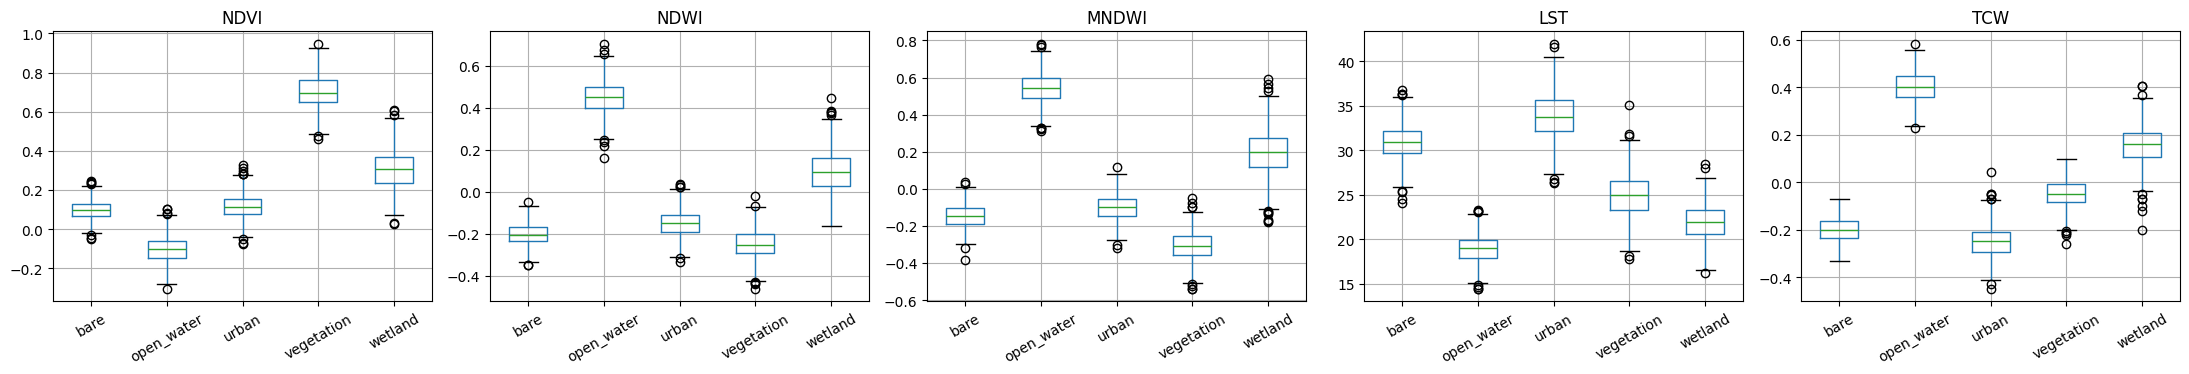

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, idx in zip(axes, PARAMS.keys()):
    df.boxplot(column=idx, by="landcover", ax=ax, rot=30)
    ax.set_title(idx.upper())
    ax.set_xlabel("")
plt.suptitle("")
plt.tight_layout()
plt.show()


## 2. Define the target class and each index's "direction"

Two design decisions live here, and both belong in your methods section, not buried in
code:

- **Which classes count as "water" for this study?** Open water only? Or open water +
  wetland, since your manuscript's framing is about wall-to-wall structure including
  wet/flooded forest? This changes what the thresholds are actually optimized for.
- **Direction**: for NDWI/MNDWI/TCW, water-like pixels sit *above* the threshold; for
  NDVI/LST, water-like pixels sit *below* it. Get this backwards and the grid search
  will silently return a useless threshold near the edge of the index's range.


In [4]:
TARGET_CLASSES = ["open_water", "wetland"]  # <- edit: e.g. ["open_water"] for a stricter open-water-only target
df["is_water"] = df["landcover"].isin(TARGET_CLASSES).astype(int)

INDEX_DIRECTION = {
    "ndvi":  "below",  # water-like pixels have LOW ndvi
    "ndwi":  "above",  # water-like pixels have HIGH ndwi
    "mndwi": "above",
    "lst":   "below",  # water-like pixels are COOLER
    "tcw":   "above",
}

print(df["is_water"].value_counts(normalize=True).rename("share"))


is_water
0    0.6
1    0.4
Name: share, dtype: float64


# Spatial Blocking to Address Autocorrelation — ROI Map

Your pasted snippet already has the right idea: assign whole **blocks** of space to a
single split (train/test/val) instead of splitting individual sample points at random.
This notebook turns that into a map so you can see *why* it matters and check it over
your actual ROI before applying it to your real sample data.

**One bug to fix first:** the snippet hardcodes `EPSG:32616` (UTM zone 16N), which is
correct for Sewanee, TN, but your ROI here —

```
ee.Geometry.BBox(-120.385, 42.491, -120.057, 42.774)
```

— sits right on the Oregon/California border, which falls in **UTM zone 10N
(EPSG:32610)**, not zone 16N. Reusing the Sewanee EPSG code on this ROI distorts the
"1 km" block size (cells stop being true 1 km squares the farther you are from zone
16N's central meridian, -87°). The cell below auto-detects the correct zone from the
ROI's centroid instead of hardcoding it, which is the safer pattern if you reuse this
across multiple study areas.

**Why blocking matters (what the map below shows):** neighboring pixels are not
independent — if a "test" pixel sits right next to a "train" pixel, the model has
effectively already seen something very close to that test pixel during training, so
test performance is inflated. Randomly assigning points one at a time produces exactly
this salt-and-pepper adjacency. Assigning whole spatial blocks to a single split instead
keeps spatially correlated neighbors together, so train/test/val are genuinely
independent of each other.


In [12]:
min_lon, min_lat, max_lon, max_lat = (
    -120.38501122715638, 42.490840210754435,
    -120.05679467442201, 42.77373785892154,
)
center_lon, center_lat = (min_lon + max_lon) / 2, (min_lat + max_lat) / 2

utm_zone = int((center_lon + 180) // 6) + 1
epsg = 32600 + utm_zone if center_lat >= 0 else 32700 + utm_zone
print(f"ROI centroid: ({center_lon:.4f}, {center_lat:.4f})")
print(f"Correct UTM zone: {utm_zone}N -> EPSG:{epsg}")

to_utm = Transformer.from_crs("EPSG:4326", f"EPSG:{epsg}", always_xy=True)
to_wgs = Transformer.from_crs(f"EPSG:{epsg}", "EPSG:4326", always_xy=True)

minx, miny = to_utm.transform(min_lon, min_lat)
maxx, maxy = to_utm.transform(max_lon, max_lat)


ROI centroid: (-120.2209, 42.6323)
Correct UTM zone: 10N -> EPSG:32610


In [24]:
block_size_m = 1000

x_starts = np.arange(math.floor(minx / block_size_m) * block_size_m, maxx, block_size_m)
y_starts = np.arange(math.floor(miny / block_size_m) * block_size_m, maxy, block_size_m)

blocks = []
for bx in x_starts:
    for by in y_starts:
        blocks.append(dict(
            block_x=int(bx // block_size_m), block_y=int(by // block_size_m),
            geom_utm=box(bx, by, bx + block_size_m, by + block_size_m),
        ))
for b in blocks:
    b["block_id"] = f"{b['block_x']}_{b['block_y']}"

rng = np.random.default_rng(RANDOM_SEED)
block_ids = [b["block_id"] for b in blocks]
shuffled = block_ids.copy()
rng.shuffle(shuffled)
n = len(shuffled)
train_ids = set(shuffled[: int(n * 0.70)])
test_ids  = set(shuffled[int(n * 0.70): int(n * 0.90)])
val_ids   = set(shuffled[int(n * 0.90):])

def split_for_block(bid):
    if bid in train_ids:
        return "train"
    elif bid in test_ids:
        return "test"
    return "val"

for b in blocks:
    b["split"] = split_for_block(b["block_id"])

print(f"{len(blocks)} blocks covering the ROI ({len(x_starts)} x {len(y_starts)})")
print("split shares:", {s: round(sum(b['split']==s for b in blocks)/len(blocks), 3) for s in ['train','test','val']})


891 blocks covering the ROI (27 x 33)
split shares: {'train': 0.699, 'test': 0.2, 'val': 0.101}


In [25]:
n_clusters = 35
points_per_cluster = 20
cluster_jitter_m = 120  # spread of points around each cluster center, in meters

pt_rng = np.random.default_rng(7)
cluster_cx = pt_rng.uniform(minx + 500, maxx - 500, n_clusters)
cluster_cy = pt_rng.uniform(miny + 500, maxy - 500, n_clusters)

pts_x, pts_y, cluster_id = [], [], []
for ci, (cx, cy) in enumerate(zip(cluster_cx, cluster_cy)):
    jx = pt_rng.normal(0, cluster_jitter_m, points_per_cluster)
    jy = pt_rng.normal(0, cluster_jitter_m, points_per_cluster)
    pts_x.extend(cx + jx)
    pts_y.extend(cy + jy)
    cluster_id.extend([ci] * points_per_cluster)

pts_x, pts_y, cluster_id = np.array(pts_x), np.array(pts_y), np.array(cluster_id)
n_points = len(pts_x)
pts_lon, pts_lat = to_wgs.transform(pts_x, pts_y)

def block_id_for_point(x, y):
    return f"{int(x // block_size_m)}_{int(y // block_size_m)}"

point_block_ids = [block_id_for_point(x, y) for x, y in zip(pts_x, pts_y)]
point_block_split = [split_for_block(bid) for bid in point_block_ids]

# naive strategy: split EACH POINT independently at random, ignoring location entirely
naive_choices = pt_rng.choice(["train", "test", "val"], size=n_points, p=[0.70, 0.20, 0.10])

# how many of the 35 clusters end up with members in more than one partition?
naive_fragmented = sum(len(set(naive_choices[cluster_id == c])) > 1 for c in range(n_clusters))
block_fragmented = sum(len(set(np.array(point_block_split)[cluster_id == c])) > 1 for c in range(n_clusters))
print(f"clusters split across >1 partition  ->  naive: {naive_fragmented}/{n_clusters}   "
      f"block-based: {block_fragmented}/{n_clusters}")


clusters split across >1 partition  ->  naive: 35/35   block-based: 16/35


In [26]:
split_colors = {"train": "#1f77b4", "test": "#ff7f0e", "val": "#2ca02c"}

m = folium.Map(location=[center_lat, center_lon], zoom_start=10, tiles="CartoDB positron")

roi_ring = [(min_lat, min_lon), (min_lat, max_lon), (max_lat, max_lon), (max_lat, min_lon), (min_lat, min_lon)]
folium.PolyLine(roi_ring, color="black", weight=2, dash_array="5,5", tooltip="ROI boundary").add_to(m)

blocks_layer = FeatureGroup(name="1 km spatial blocks (colored by split)", show=True)
for b in blocks:
    ring_wgs = [to_wgs.transform(x, y)[::-1] for x, y in b["geom_utm"].exterior.coords]
    color = split_colors[b["split"]]
    folium.Polygon(
        ring_wgs, color=color, weight=0.5, fill=True, fill_color=color, fill_opacity=0.25,
        tooltip=f"block {b['block_id']} -> {b['split']}",
    ).add_to(blocks_layer)
blocks_layer.add_to(m)

naive_layer = FeatureGroup(name="Naive split: random per POINT (ignores location)", show=False)
for lat, lon, choice in zip(pts_lat, pts_lon, naive_choices):
    folium.CircleMarker((lat, lon), radius=4, color=split_colors[choice], fill=True,
                         fill_color=split_colors[choice], fill_opacity=0.9, weight=1).add_to(naive_layer)
naive_layer.add_to(m)

block_split_layer = FeatureGroup(name="Block-based split: points inherit their block's split", show=True)
for lat, lon, split in zip(pts_lat, pts_lon, point_block_split):
    folium.CircleMarker((lat, lon), radius=4, color=split_colors[split], fill=True,
                         fill_color=split_colors[split], fill_opacity=0.9, weight=1).add_to(block_split_layer)
block_split_layer.add_to(m)

legend_html = '''
<div style="position: fixed; bottom: 30px; left: 30px; z-index: 9999; background: white;
            padding: 10px 14px; border: 1px solid #999; border-radius: 4px; font-size: 13px;">
<b>Split</b><br>
<span style="color:#1f77b4;">&#9632;</span> train (70%)<br>
<span style="color:#ff7f0e;">&#9632;</span> test (20%)<br>
<span style="color:#2ca02c;">&#9632;</span> val (10%)
</div>
'''
m.get_root().html.add_child(folium.Element(legend_html))
LayerControl(collapsed=False).add_to(m)
m


## 3. Train / test split — don't tune and evaluate on the same pixels

This is the most common way threshold-tuning studies fool themselves: if you grid-search
on the full dataset and then report the F1 of that same threshold on the same data, the
number is optimistic by construction (the threshold was *chosen* to maximize it on that
exact sample). Holding out a test set — and below, doing k-fold CV within the training
set as well — gives you an estimate of how the threshold generalizes, which is the
number that's actually defensible in a manuscript.

For real GEE data, also think about **spatial autocorrelation**: a random pixel split is
optimistic if your truth points are clustered (neighboring pixels in the same wetland
polygon are not independent samples). A cleaner split groups by polygon/patch ID, not by
pixel — worth implementing once you move off the synthetic data.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    df[list(PARAMS.keys())], df["is_water"],
    test_size=0.3, stratify=df["is_water"], random_state=RANDOM_SEED,
)
print(f"train: {len(X_train)}  test: {len(X_test)}")


train: 2100  test: 900


## 4. The grid search core

For a single index: sweep candidate thresholds across its observed range (trimmed to the
0.5–99.5 percentile so one outlier pixel doesn't stretch the grid uselessly), classify
every pixel as water/not-water at each candidate threshold, and score it against the
truth labels with a confusion matrix.

Metrics computed at every threshold:

- **precision / recall (sensitivity) / specificity** — the basic confusion-matrix rates.
- **F1** — harmonic mean of precision and recall; balanced default for picking "the" best threshold.
- **IoU** (intersection-over-union) — stricter than F1, penalizes both omission and commission more symmetrically; common in segmentation-style validation.
- **Youden's J** (sensitivity + specificity − 1) — maximized at the threshold that best separates the two ROC-curve extremes; a common alternative criterion when you care about over- and under-classification equally rather than precision specifically.

Pick whichever metric matches what actually matters for your downstream use (e.g. if
false positives over urban are costly, weight precision more; if missing flooded forest
patches is costly, weight recall/IoU more).


In [6]:
def grid_search_threshold(values, labels, direction, n_steps=200):
    '''Sweep thresholds for one index and score each against binary truth labels.

    values:    1D array of index values for each pixel
    labels:    1D array of 0/1 truth labels (1 = target class)
    direction: "above" if target class has HIGHER values, "below" if LOWER
    n_steps:   number of candidate thresholds to evaluate

    Returns a DataFrame with one row per candidate threshold and its metrics.
    '''
    lo, hi = np.percentile(values, [0.5, 99.5])
    thresholds = np.linspace(lo, hi, n_steps)
    rows = []
    for t in thresholds:
        pred = (values >= t) if direction == "above" else (values <= t)
        tn, fp, fn, tp = confusion_matrix(labels, pred, labels=[0, 1]).ravel()
        sens = tp / (tp + fn) if (tp + fn) else 0.0
        spec = tn / (tn + fp) if (tn + fp) else 0.0
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        f1   = 2 * prec * sens / (prec + sens) if (prec + sens) else 0.0
        iou  = tp / (tp + fp + fn) if (tp + fp + fn) else 0.0
        youden = sens + spec - 1
        rows.append(dict(threshold=t, precision=prec, recall=sens, specificity=spec,
                          f1=f1, iou=iou, youden_j=youden))
    return pd.DataFrame(rows)


## 5. Per-index threshold selection, with k-fold cross-validation

Rather than running the grid search once on the whole training set, we run it on each
of k folds and average the resulting optimal threshold. This gives both a point estimate
and a sense of how stable that threshold is (`threshold_std`) — a wide spread across
folds is itself a useful finding (it tells you the index's "best" cutoff is sensitive to
sample composition, which is worth flagging in the manuscript).


In [7]:
def cv_optimal_threshold(values, labels, direction, metric="f1", n_splits=5, n_steps=150, seed=RANDOM_SEED):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    fold_thresholds = []
    for train_idx, _ in skf.split(values, labels):
        gs = grid_search_threshold(values[train_idx], labels[train_idx], direction, n_steps=n_steps)
        fold_thresholds.append(gs.loc[gs[metric].idxmax(), "threshold"])
    return float(np.mean(fold_thresholds)), float(np.std(fold_thresholds)), fold_thresholds


cv_curves = {}      # full grid-search curve per index (on the full training set, for plotting)
summary_rows = []

for idx, direction in INDEX_DIRECTION.items():
    mean_t, std_t, fold_thresholds = cv_optimal_threshold(X_train[idx].values, y_train.values, direction)
    cv_curves[idx] = grid_search_threshold(X_train[idx].values, y_train.values, direction)

    # evaluate the CV-averaged threshold on the held-out test set
    pred_test = (X_test[idx].values >= mean_t) if direction == "above" else (X_test[idx].values <= mean_t)
    tn, fp, fn, tp = confusion_matrix(y_test.values, pred_test, labels=[0, 1]).ravel()
    sens = tp / (tp + fn) if (tp + fn) else 0.0
    spec = tn / (tn + fp) if (tn + fp) else 0.0
    prec = tp / (tp + fp) if (tp + fp) else 0.0
    f1   = 2 * prec * sens / (prec + sens) if (prec + sens) else 0.0

    summary_rows.append(dict(
        index=idx, direction=direction,
        threshold_mean=round(mean_t, 4), threshold_std=round(std_t, 4),
        test_f1=round(f1, 3), test_sensitivity=round(sens, 3), test_specificity=round(spec, 3),
    ))

summary = pd.DataFrame(summary_rows).sort_values("test_f1", ascending=False).reset_index(drop=True)
summary


,index,direction,threshold_mean,threshold_std,test_f1,test_sensitivity,test_specificity
0,mndwi,above,0.0388,0.0028,0.980,0.967,0.996
1,ndwi,above,-0.0447,0.0020,0.978,0.978,0.985
2,tcw,above,0.0574,0.0070,0.957,0.928,0.993
3,lst,below,24.2629,0.1764,0.867,0.906,0.878
4,ndvi,below,0.5124,0.0018,0.665,0.986,0.346


## 6. Threshold–performance curves

Plotting the full curve (not just the single optimal point) matters: a sharp, narrow
peak means the threshold is well-constrained by your data; a broad, flat peak means many
threshold values perform almost equally well, so the "optimal" value reported in the
table above is somewhat arbitrary and shouldn't be over-interpreted to many decimal
places. Watch in particular for non-monotonic curves (multiple local peaks) — that's a
sign the index conflates the target class with more than one confuser class across
different parts of its range.


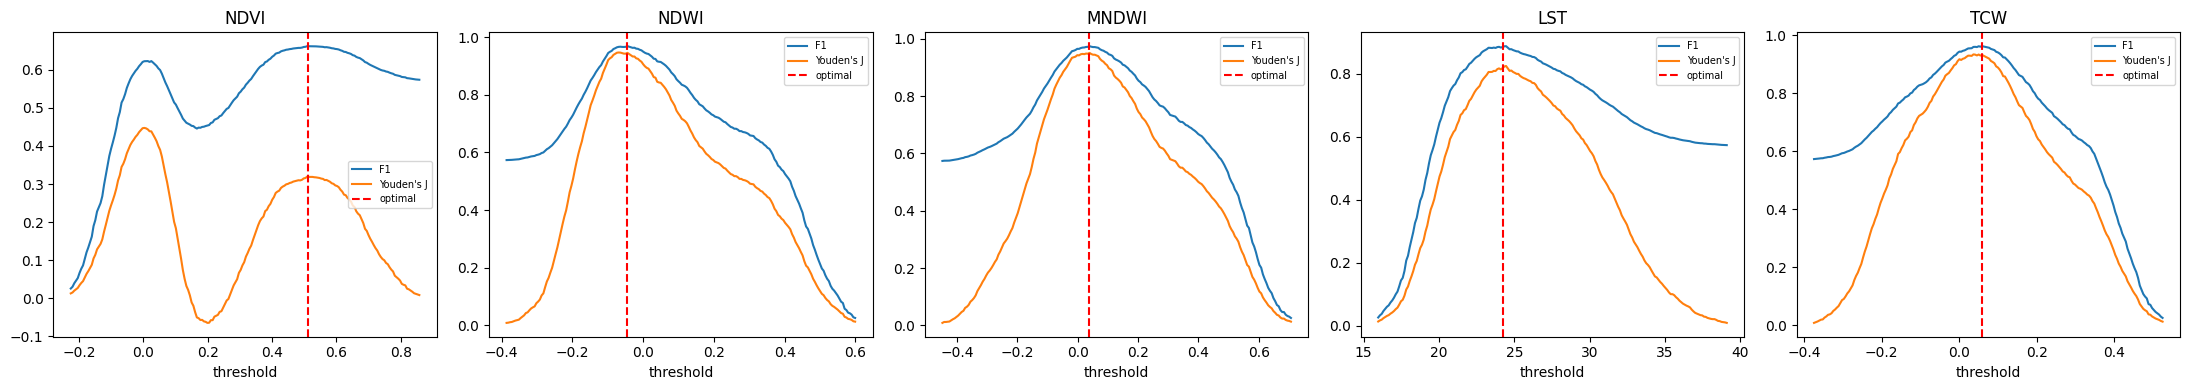

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))
for ax, (idx, gs) in zip(axes, cv_curves.items()):
    ax.plot(gs["threshold"], gs["f1"], label="F1")
    ax.plot(gs["threshold"], gs["youden_j"], label="Youden's J")
    best_t = summary.loc[summary["index"] == idx, "threshold_mean"].values[0]
    ax.axvline(best_t, color="red", linestyle="--", label="optimal")
    ax.set_title(idx.upper())
    ax.set_xlabel("threshold")
    ax.legend(fontsize=7)
plt.tight_layout()
plt.show()


## 7. Final validation table

The `summary` table above already reports test-set performance for the CV-averaged
threshold per index — this is the version of the result that's safe to put in a
manuscript table, since it wasn't tuned on the data it's scored against.

In this synthetic example MNDWI and NDWI come out on top (as expected — they're built
specifically to isolate water), LST is a usable but noisier solo discriminator, and NDVI
alone performs worst with a non-monotonic curve, because low NDVI doesn't distinguish
water from bare soil/urban — only a combination of indices resolves that ambiguity. That
pattern (one or two indices doing most of the separating work, others mainly useful in
combination) is a common and reportable finding, not a failure of the method.


In [9]:
print(summary.to_string(index=False))


index direction  threshold_mean  threshold_std  test_f1  test_sensitivity  test_specificity
mndwi     above          0.0388         0.0028    0.980             0.967             0.996
 ndwi     above         -0.0447         0.0020    0.978             0.978             0.985
  tcw     above          0.0574         0.0070    0.957             0.928             0.993
  lst     below         24.2629         0.1764    0.867             0.906             0.878
 ndvi     below          0.5124         0.0018    0.665             0.986             0.346


## 8. Bonus: joint 2D grid search (why brute-force doesn't scale to 5 indices)

A single-index threshold is a 1D sweep. Two indices jointly is a 2D grid (the cell below
does a 40×40 sweep = 1,600 evaluations, still fast). Five indices jointly, at the same
resolution, is 40⁵ ≈ 100 million evaluations — not something to brute-force in a
notebook.

The 2D version below is mainly diagnostic: it shows whether combining your two best
single indices buys you anything over either alone, and what the trade-off surface looks
like (a sharp diagonal ridge means the two indices are partly redundant; a sharp corner
means they're complementary and both real constraints help).

For combining more than 2–3 indices in practice, better options than brute-force grid
search include: a depth-1 decision tree per index (sklearn's `DecisionTreeClassifier`
finds the Gini/entropy-optimal single split essentially instantly — equivalent to this
grid search but faster), a shallow decision tree or logistic regression across all 5
indices jointly (lets you keep "thresholds" interpretable as splits while letting the
model handle the combination), or a smarter search strategy (coordinate ascent: optimize
one index at a time holding others fixed, iterate to convergence; or `scipy.optimize`).


Joint optimum: mndwi=-0.0271, ndwi=-0.0961, F1=0.980


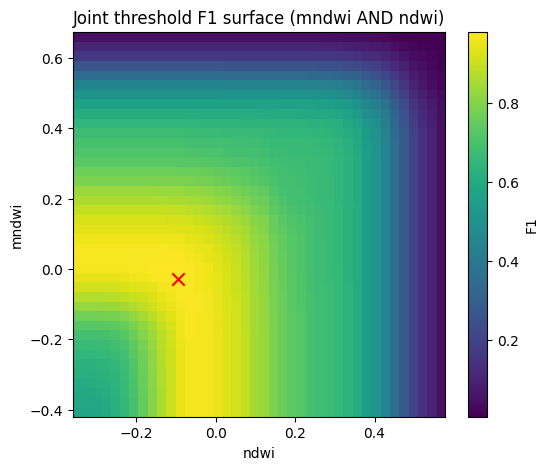

In [10]:
def joint_grid_search(v1, v2, labels, dir1, dir2, n_steps=40):
    lo1, hi1 = np.percentile(v1, [1, 99])
    lo2, hi2 = np.percentile(v2, [1, 99])
    t1s = np.linspace(lo1, hi1, n_steps)
    t2s = np.linspace(lo2, hi2, n_steps)
    f1_grid = np.zeros((n_steps, n_steps))
    for i, t1 in enumerate(t1s):
        c1 = (v1 >= t1) if dir1 == "above" else (v1 <= t1)
        for j, t2 in enumerate(t2s):
            c2 = (v2 >= t2) if dir2 == "above" else (v2 <= t2)
            pred = c1 & c2
            tn, fp, fn, tp = confusion_matrix(labels, pred, labels=[0, 1]).ravel()
            prec = tp / (tp + fp) if (tp + fp) else 0.0
            rec  = tp / (tp + fn) if (tp + fn) else 0.0
            f1_grid[i, j] = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    bi, bj = np.unravel_index(np.argmax(f1_grid), f1_grid.shape)
    return t1s, t2s, f1_grid, t1s[bi], t2s[bj], f1_grid[bi, bj]


top2 = summary["index"].iloc[:2].tolist()
i1, i2 = top2[0], top2[1]
t1s, t2s, grid, bt1, bt2, bf1 = joint_grid_search(
    X_train[i1].values, X_train[i2].values, y_train.values,
    INDEX_DIRECTION[i1], INDEX_DIRECTION[i2], n_steps=40,
)
print(f"Joint optimum: {i1}={bt1:.4f}, {i2}={bt2:.4f}, F1={bf1:.3f}")

plt.figure(figsize=(6, 5))
plt.imshow(grid, origin="lower", aspect="auto",
           extent=[t2s.min(), t2s.max(), t1s.min(), t1s.max()], cmap="viridis")
plt.colorbar(label="F1")
plt.scatter([bt2], [bt1], color="red", marker="x", s=80)
plt.xlabel(i2)
plt.ylabel(i1)
plt.title(f"Joint threshold F1 surface ({i1} AND {i2})")
plt.show()


## 9. Swapping in your real GEE-derived data

One thing that needs to change is `generate_synthetic_dataset()` — everything from
section 2 onward operates on a plain DataFrame with one column per index and a
`landcover` column, regardless of where it came from.

Also address what is "Truth"

To build that DataFrame from your actual monthly composite and truth points/polygons in
Earth Engine:

```python
import ee, geemap
ee.Initialize()

# monthly_composite: ee.Image with bands named to match your indices, e.g.
#   .select(["NDVI", "NDWI", "MNDWI", "LST", "TCW"])
# truth_fc: ee.FeatureCollection of points/polygons with a "landcover" property

sampled_fc = monthly_composite.sampleRegions(
    collection=truth_fc,
    properties=["landcover"],
    scale=10,          # match your target resolution
    tileScale=4,        # bump up if you hit "user memory limit exceeded" on large truth sets
    geometries=False,
)

df = geemap.ee_to_df(sampled_fc)
df.columns = df.columns.str.lower()  # match the lowercase names used above
```

A few things worth deciding deliberately when you do this, since they directly affect
how defensible the resulting thresholds are:

- **Polygon-aware splitting.** If `truth_fc` has polygons (a wetland patch sampled at
  many pixels), do the train/test split — and the CV folds — by polygon ID, not by
  pixel, or you'll leak spatially correlated pixels across train/test and overstate
  performance.
- **Class balance.** If open water and wetland are rare relative to urban/bare/vegetation
  in your truth set (likely), make sure `stratify=` is doing its job, and consider
  reporting precision/recall separately rather than leaning on accuracy, which gets
  inflated by the majority "not water" class.
- **Per-month or per-composite thresholds?** A threshold tuned on a single monthly
  composite may not transfer to a different month (different illumination, phenology,
  water level) — if your wall-to-wall product spans multiple months, it's worth checking
  whether one threshold per index holds up across them, or whether you need
  season-specific thresholds, which is itself worth reporting in the manuscript.
